# IBM HR Attrition — Workforce Analysis

This notebook explores the general characteristics of the sampled IBM workforce, including its demographic, organizational, educational, tenure, and income distributions.

The analysis uses the cleaned dataset created in the data-preparation notebook.

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Processed Dataset

In [2]:
df = pd.read_csv("../data/processed/cleaned_hr_data.csv")

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,...,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,AgeGroup,TenureGroup,YearsInCurrentRoleGroup,IncomeGroup
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,...,0,1,6,4,0,5,36–45,Established (6–10),3–5 years,5000–7999
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,...,3,3,10,7,1,7,46–55,Established (6–10),6–10 years,5000–7999
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,...,3,3,0,0,0,0,36–45,New Employees (0–2),0–2 years,Under 3000
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,...,3,3,8,7,3,0,26–35,Established (6–10),6–10 years,Under 3000
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,...,3,3,2,2,2,2,26–35,New Employees (0–2),0–2 years,3000–4999


In [4]:
df.shape

(1470, 36)

## 3. Employee Overview

In [5]:
total_employees = len(df)
department_count = df["Department"].nunique()
job_role_count = df["JobRole"].nunique()

In [6]:
overview_table = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Departments",
        "Job Roles"
    ],
    "Value": [
        total_employees,
        department_count,
        job_role_count
    ]
})

overview_table

,Metric,Value
0,Total Employees,1470
1,Departments,3
2,Job Roles,9


**Observation:** The dataset contains 1,470 IBM employees working across 9 job roles and 3 departments.

In [8]:
### 3.1 Average Employee Characteristics

In [9]:
average_age = df["Age"].mean()
average_income = df["MonthlyIncome"].mean()
average_tenure = df["YearsAtCompany"].mean()

In [10]:
average_employee_table = pd.DataFrame({
    "Metric": [
        "Age",
        "Monthly Income",
        "Years at Company"
    ],
    "Average": [
        average_age,
        average_income,
        average_tenure
    ]
})

average_employee_table["Average"] = (
    average_employee_table["Average"].round(2)
)

average_employee_table

,Metric,Average
0,Age,36.92
1,Monthly Income,6502.93
2,Years at Company,7.01


**Observation:** The average employee is approximately 37 years old, earns a monthly income of 6,502.93, and has worked at the company for approximately 7 years.

### 3.2 Gender and Overtime Overview

In [12]:
gender_percentage = (
    df["Gender"]
    .value_counts(normalize=True)
    .mul(100)
)

overtime_percentage = (
    df["OverTime"]
    .value_counts(normalize=True)
    .mul(100)
)

In [13]:
distribution_table = pd.DataFrame({
    "Metric": [
        "Gender",
        "Overtime"
    ],
    "Distribution": [
        (
            f"Male: {gender_percentage['Male']:.0f}% / "
            f"Female: {gender_percentage['Female']:.0f}%"
        ),
        (
            f"Yes: {overtime_percentage['Yes']:.2f}% / "
            f"No: {overtime_percentage['No']:.2f}%"
        )
    ]
})

distribution_table

,Metric,Distribution
0,Gender,Male: 60% / Female: 40%
1,Overtime,Yes: 28.30% / No: 71.70%


**Observation:** The workforce contains slightly more male than female employees. Approximately 30% of employees work overtime, while the majority do not.

## 4. Department Distribution

In [14]:
department_counts = df["Department"].value_counts()

In [15]:
department_count_table = pd.DataFrame({
    "Department": department_counts.index,
    "Employees": department_counts.values
})

department_count_table

,Department,Employees
0,Research & Development,961
1,Sales,446
2,Human Resources,63


In [16]:
department_percentages = (
    df["Department"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [17]:
department_percentage_table = pd.DataFrame({
    "Department": department_percentages.index,
    "Percentage": department_percentages.values
})

department_percentage_table

,Department,Percentage
0,Research & Development,65.37
1,Sales,30.34
2,Human Resources,4.29


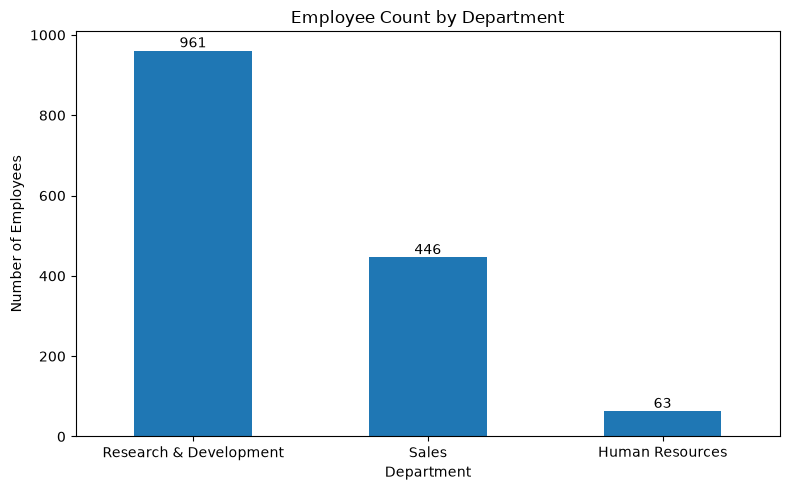

In [18]:
plt.figure(figsize=(8, 5))

ax = department_counts.plot(kind="bar")

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

**Observation:** Most employees in the sampled workforce work in Research and Development. Approximately 30% work in Sales, while slightly under 5% work in Human Resources.

## 5. Job Role Distribution

In [20]:
job_role_counts = df["JobRole"].value_counts()

In [21]:
job_role_count_table = pd.DataFrame({
    "Job Role": job_role_counts.index,
    "Employees": job_role_counts.values
})

job_role_count_table

,Job Role,Employees
0,Sales Executive,326
1,Research Scientist,292
2,Laboratory Technician,259
3,Manufacturing Director,145
4,Healthcare Representative,131
5,Manager,102
6,Sales Representative,83
7,Research Director,80
8,Human Resources,52


In [22]:
job_role_percentages = (
    df["JobRole"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

In [23]:
job_role_percentage_table = pd.DataFrame({
    "Job Role": job_role_percentages.index,
    "Percentage": job_role_percentages.values
})

job_role_percentage_table

,Job Role,Percentage
0,Sales Executive,22.18
1,Research Scientist,19.86
2,Laboratory Technician,17.62
3,Manufacturing Director,9.86
4,Healthcare Representative,8.91
5,Manager,6.94
6,Sales Representative,5.65
7,Research Director,5.44
8,Human Resources,3.54


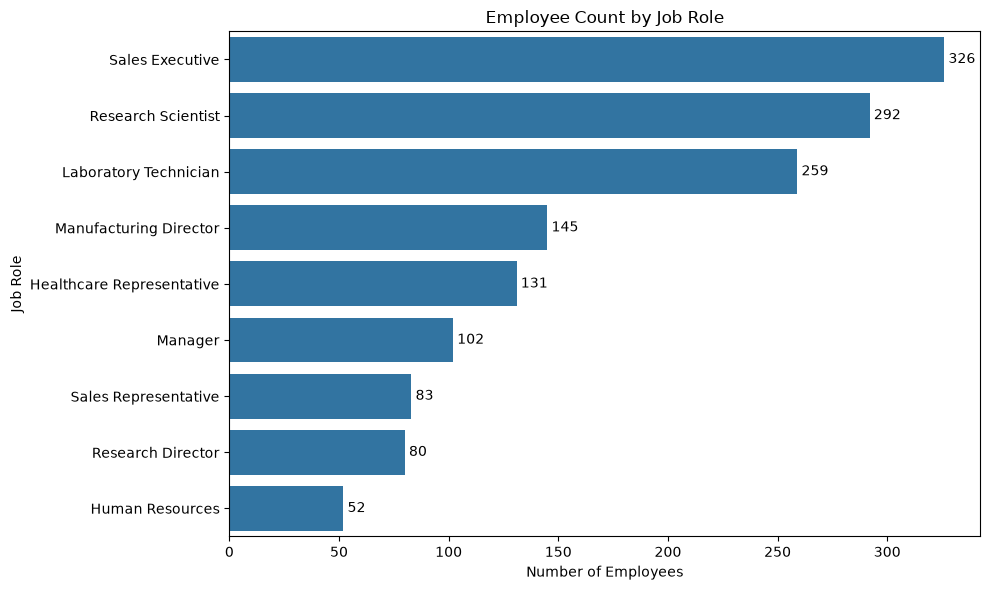

In [24]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=job_role_count_table,
    x="Employees",
    y="Job Role"
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Employee Count by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

plt.tight_layout()
plt.show()

**Observation:** Sales Executive, Research Scientist, and Laboratory Technician are the most common job roles, each representing approximately 18–22% of the workforce. These roles are concentrated across the two largest departments: Sales and Research and Development.

## 6. Age Distribution

In [25]:
df["Age"].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

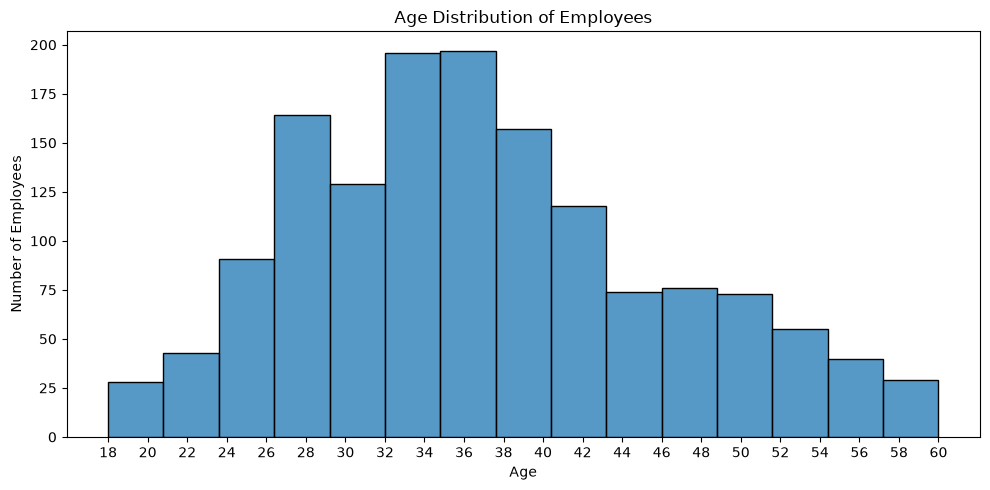

In [28]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15
)

plt.title("Age Distribution of Employees")
plt.xlabel("Age")
plt.ylabel("Number of Employees")
plt.xticks(range(18, 61, 2))

plt.tight_layout()
plt.show()

In [27]:
age_group_order = [
    "18–25",
    "26–35",
    "36–45",
    "46–55",
    "56–60"
]

In [29]:
age_group_counts = (
    df["AgeGroup"]
    .value_counts()
    .reindex(age_group_order)
)

age_group_counts

AgeGroup
18–25    123
26–35    606
36–45    468
46–55    226
56–60     47
Name: count, dtype: int64

In [30]:
age_group_percentages = (
    df["AgeGroup"]
    .value_counts(normalize=True)
    .reindex(age_group_order)
    .mul(100)
    .round(2)
)

age_group_percentages

AgeGroup
18–25     8.37
26–35    41.22
36–45    31.84
46–55    15.37
56–60     3.20
Name: proportion, dtype: float64

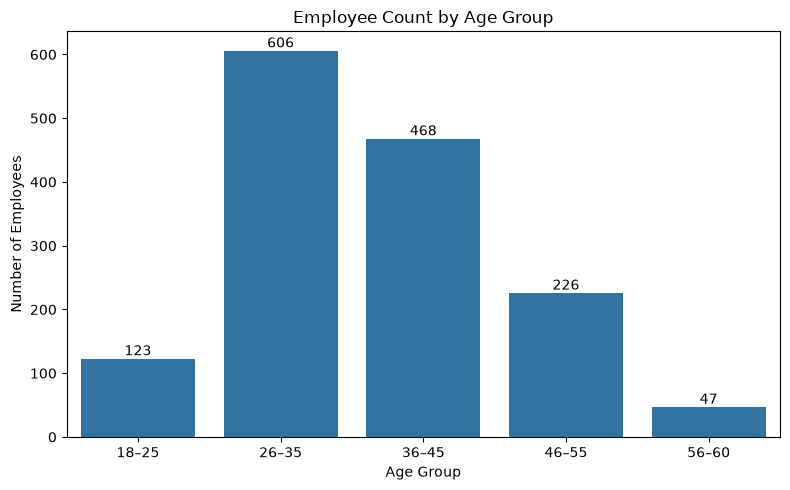

In [31]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=age_group_counts.index,
    y=age_group_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Employee Count by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

**Observation:** Employees aged 26–45 make up the majority of the sampled workforce. Individual ages around 28, 34, and 36 are especially common, while the youngest and oldest age groups contain considerably fewer employees.

## 7. Education Level Distribution

In [32]:
education_labels = {
    1: "Below College",
    2: "College",
    3: "Bachelor",
    4: "Master",
    5: "Doctor"
}

In [33]:
education_distribution = (
    df["Education"]
    .value_counts()
    .sort_index()
    .rename_axis("Level")
    .reset_index(name="Employees")
)

In [34]:
education_distribution["Education Level"] = (
    education_distribution["Level"].map(education_labels)
)

In [35]:
education_distribution = education_distribution[
    ["Level", "Education Level", "Employees"]
]

education_distribution

,Level,Education Level,Employees
0,1,Below College,170
1,2,College,282
2,3,Bachelor,572
3,4,Master,398
4,5,Doctor,48


In [36]:
education_percentages = (
    df["Education"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .rename_axis("Level")
    .reset_index(name="Percentage")
)

In [37]:
education_percentages["Education Level"] = (
    education_percentages["Level"].map(education_labels)
)

education_percentages = education_percentages[
    ["Level", "Education Level", "Percentage"]
]

education_percentages

,Level,Education Level,Percentage
0,1,Below College,11.56
1,2,College,19.18
2,3,Bachelor,38.91
3,4,Master,27.07
4,5,Doctor,3.27


In [38]:
education_distribution["Level Label"] = (
    education_distribution["Level"].astype(str)
    + " - "
    + education_distribution["Education Level"]
)

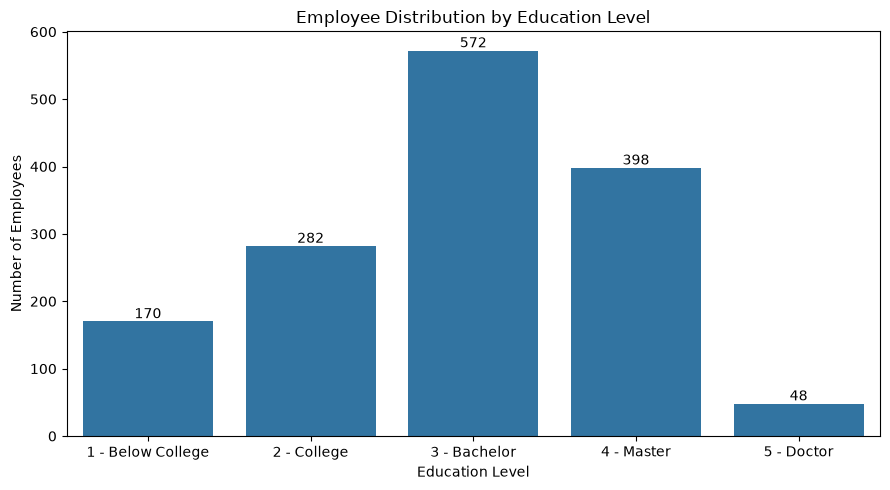

In [39]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=education_distribution,
    x="Level Label",
    y="Employees"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Employee Distribution by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

**Observation:** Bachelor’s and master’s degrees are the most common education levels in the sampled workforce, with bachelor’s degrees being the most prevalent. Doctoral degrees are the least common.

## 8. Education Field Distribution

In [40]:
education_field_counts = df["EducationField"].value_counts()

education_field_counts

EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

In [41]:
education_field_percentages = (
    df["EducationField"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

education_field_percentages

EducationField
Life Sciences       41.22
Medical             31.56
Marketing           10.82
Technical Degree     8.98
Other                5.58
Human Resources      1.84
Name: proportion, dtype: float64

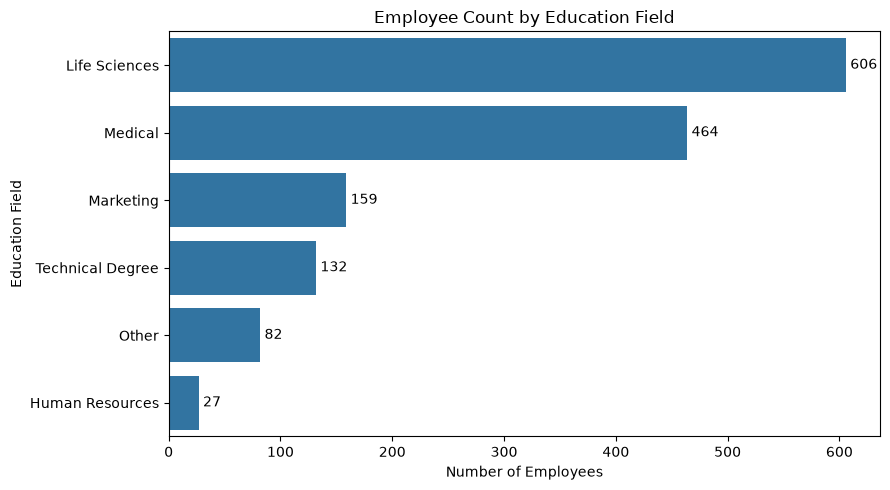

In [42]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=education_field_counts.values,
    y=education_field_counts.index
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Employee Count by Education Field")
plt.xlabel("Number of Employees")
plt.ylabel("Education Field")

plt.tight_layout()
plt.show()

**Observation:** Life Sciences and Medical are the most common fields of education in the sampled workforce, together representing the majority of employees. Other educational fields are considerably less represented.

## 9. Marital Status Distribution

In [43]:
marital_status_counts = df["MaritalStatus"].value_counts()

marital_status_counts

MaritalStatus
Married     673
Single      470
Divorced    327
Name: count, dtype: int64

In [44]:
marital_status_percentages = (
    df["MaritalStatus"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

marital_status_percentages

MaritalStatus
Married     45.78
Single      31.97
Divorced    22.24
Name: proportion, dtype: float64

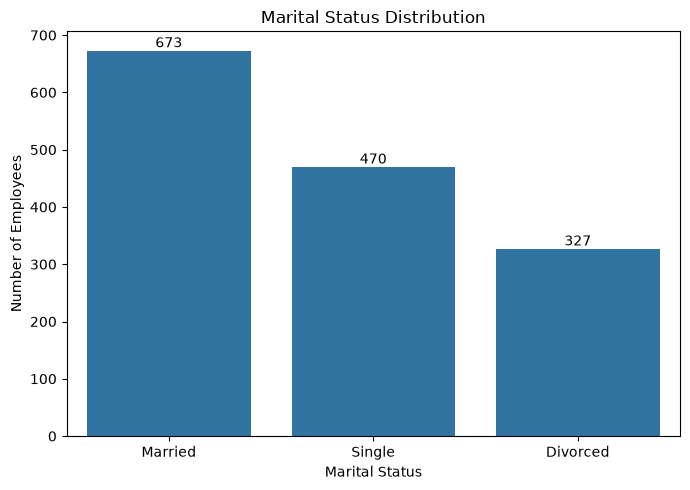

In [45]:
plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=marital_status_counts.index,
    y=marital_status_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Marital Status Distribution")
plt.xlabel("Marital Status")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

**Observation:** Married employees make up the largest marital-status group in the sampled workforce, followed by single employees. Divorced employees are the least represented.

## 10. Business Travel Frequency Distribution

In [46]:
business_travel_counts = df["BusinessTravel"].value_counts()

business_travel_counts

BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

In [47]:
business_travel_percentages = (
    df["BusinessTravel"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

business_travel_percentages

BusinessTravel
Travel_Rarely        70.95
Travel_Frequently    18.84
Non-Travel           10.20
Name: proportion, dtype: float64

In [48]:
business_travel_labels = {
    "Travel_Rarely": "Travel Rarely",
    "Travel_Frequently": "Travel Frequently",
    "Non-Travel": "Non-Travel"
}

In [49]:
business_travel_table = business_travel_counts.rename_axis(
    "Business Travel"
).reset_index(name="Employees")

business_travel_table["Business Travel"] = (
    business_travel_table["Business Travel"]
    .map(business_travel_labels)
)

business_travel_table

,Business Travel,Employees
0,Travel Rarely,1043
1,Travel Frequently,277
2,Non-Travel,150


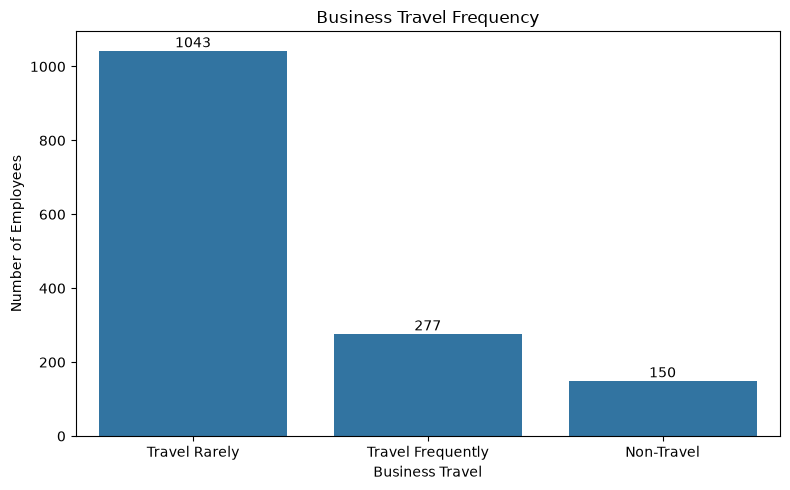

In [50]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=business_travel_table,
    x="Business Travel",
    y="Employees"
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Business Travel Frequency")
plt.xlabel("Business Travel")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

**Observation:** Most employees in the sampled workforce travel rarely for business. Frequent business travel is considerably less common, while employees who do not travel form the smallest group.

## 11. Employee Tenure Overview

In [51]:
tenure_counts = (
    df["YearsAtCompany"]
    .value_counts()
    .sort_index()
)

tenure_counts

YearsAtCompany
0      44
1     171
2     127
3     128
4     110
5     196
6      76
7      90
8      80
9      82
10    120
11     32
12     14
13     24
14     18
15     20
16     12
17      9
18     13
19     11
20     27
21     14
22     15
23      2
24      6
25      4
26      4
27      2
29      2
30      1
31      3
32      3
33      5
34      1
36      2
37      1
40      1
Name: count, dtype: int64

In [52]:
tenure_percentages = (
    df["YearsAtCompany"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

tenure_percentages

YearsAtCompany
0      2.99
1     11.63
2      8.64
3      8.71
4      7.48
5     13.33
6      5.17
7      6.12
8      5.44
9      5.58
10     8.16
11     2.18
12     0.95
13     1.63
14     1.22
15     1.36
16     0.82
17     0.61
18     0.88
19     0.75
20     1.84
21     0.95
22     1.02
23     0.14
24     0.41
25     0.27
26     0.27
27     0.14
29     0.14
30     0.07
31     0.20
32     0.20
33     0.34
34     0.07
36     0.14
37     0.07
40     0.07
Name: proportion, dtype: float64

In [53]:
tenure_group_order = [
    "New Employees (0–2)",
    "Early Career (3–5)",
    "Established (6–10)",
    "Experienced (11–20)",
    "Long Tenure (21+)"
]

In [54]:
tenure_group_counts = (
    df["TenureGroup"]
    .value_counts()
    .reindex(tenure_group_order)
)

tenure_group_counts

TenureGroup
New Employees (0–2)    342
Early Career (3–5)     434
Established (6–10)     448
Experienced (11–20)    180
Long Tenure (21+)       66
Name: count, dtype: int64

In [55]:
tenure_group_percentages = (
    df["TenureGroup"]
    .value_counts(normalize=True)
    .reindex(tenure_group_order)
    .mul(100)
    .round(2)
)

tenure_group_percentages

TenureGroup
New Employees (0–2)    23.27
Early Career (3–5)     29.52
Established (6–10)     30.48
Experienced (11–20)    12.24
Long Tenure (21+)       4.49
Name: proportion, dtype: float64

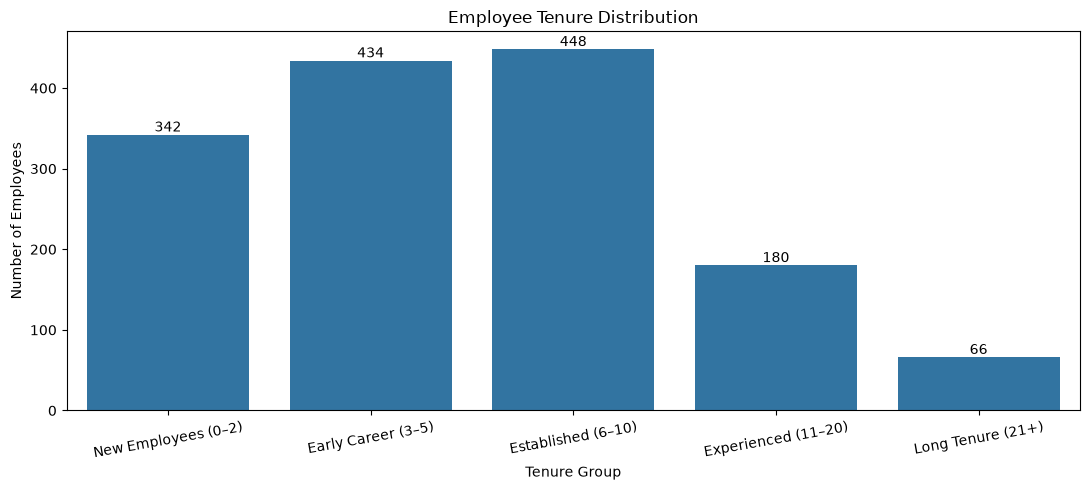

In [56]:
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    x=tenure_group_counts.index,
    y=tenure_group_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Employee Tenure Distribution")
plt.xlabel("Tenure Group")
plt.ylabel("Number of Employees")
plt.xticks(rotation=10)

plt.tight_layout()
plt.show()

**Observation:** Employee tenure is concentrated in the shorter-tenure groups, with most sampled employees having worked at the company for no more than 10 years. Employees with more than 20 years at the company form the smallest group.

## 12. Years in Current Role Distribution

In [57]:
years_in_role_counts = (
    df["YearsInCurrentRole"]
    .value_counts()
    .sort_index()
)

years_in_role_counts

YearsInCurrentRole
0     244
1      57
2     372
3     135
4     104
5      36
6      37
7     222
8      89
9      67
10     29
11     22
12     10
13     14
14     11
15      8
16      7
17      4
18      2
Name: count, dtype: int64

In [58]:
years_in_role_percentages = (
    df["YearsInCurrentRole"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

years_in_role_percentages

YearsInCurrentRole
0     16.60
1      3.88
2     25.31
3      9.18
4      7.07
5      2.45
6      2.52
7     15.10
8      6.05
9      4.56
10     1.97
11     1.50
12     0.68
13     0.95
14     0.75
15     0.54
16     0.48
17     0.27
18     0.14
Name: proportion, dtype: float64

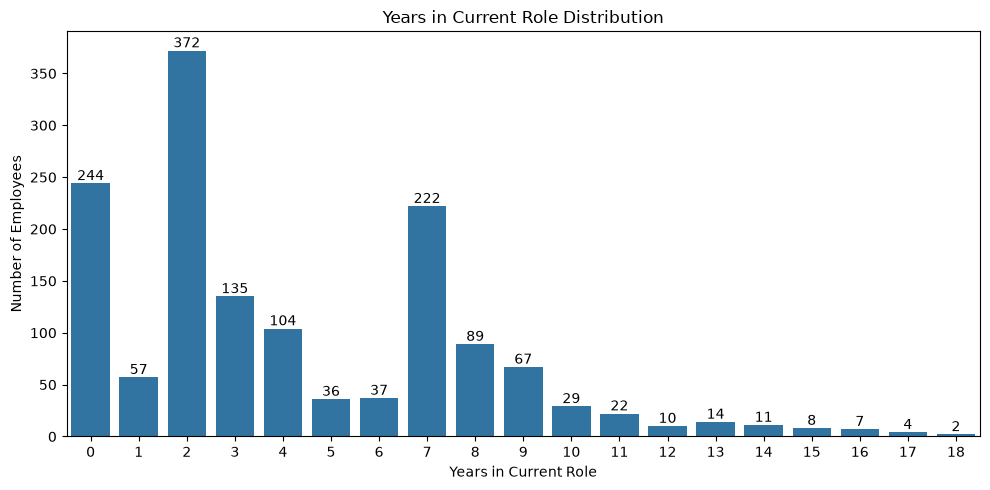

In [59]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=years_in_role_counts.index,
    y=years_in_role_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Years in Current Role Distribution")
plt.xlabel("Years in Current Role")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

In [60]:
years_in_role_group_order = [
    "0–2 years",
    "3–5 years",
    "6–10 years",
    "11+ years"
]

In [61]:
years_in_role_group_counts = (
    df["YearsInCurrentRoleGroup"]
    .value_counts()
    .reindex(years_in_role_group_order)
)

years_in_role_group_counts

YearsInCurrentRoleGroup
0–2 years     673
3–5 years     275
6–10 years    444
11+ years      78
Name: count, dtype: int64

In [62]:
years_in_role_group_percentages = (
    df["YearsInCurrentRoleGroup"]
    .value_counts(normalize=True)
    .reindex(years_in_role_group_order)
    .mul(100)
    .round(2)
)

years_in_role_group_percentages

YearsInCurrentRoleGroup
0–2 years     45.78
3–5 years     18.71
6–10 years    30.20
11+ years      5.31
Name: proportion, dtype: float64

**Observation:** Most employees have spent relatively little time in their current role, with especially high concentrations at 0, 2, and 7 years. Overall, the 0–2 year group is the most common, while relatively few employees have remained in the same role for more than 10 years.

## 13. Years Since Last Promotion

In [63]:
df["YearsSinceLastPromotion"].describe()

count    1470.000000
mean        2.187755
std         3.222430
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        15.000000
Name: YearsSinceLastPromotion, dtype: float64

In [64]:
years_since_promotion_counts = (
    df["YearsSinceLastPromotion"]
    .value_counts()
    .sort_index()
)

years_since_promotion_counts

YearsSinceLastPromotion
0     581
1     357
2     159
3      52
4      61
5      45
6      32
7      76
8      18
9      17
10      6
11     24
12     10
13     10
14      9
15     13
Name: count, dtype: int64

In [65]:
years_since_promotion_percentages = (
    df["YearsSinceLastPromotion"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

years_since_promotion_percentages

YearsSinceLastPromotion
0     39.52
1     24.29
2     10.82
3      3.54
4      4.15
5      3.06
6      2.18
7      5.17
8      1.22
9      1.16
10     0.41
11     1.63
12     0.68
13     0.68
14     0.61
15     0.88
Name: proportion, dtype: float64

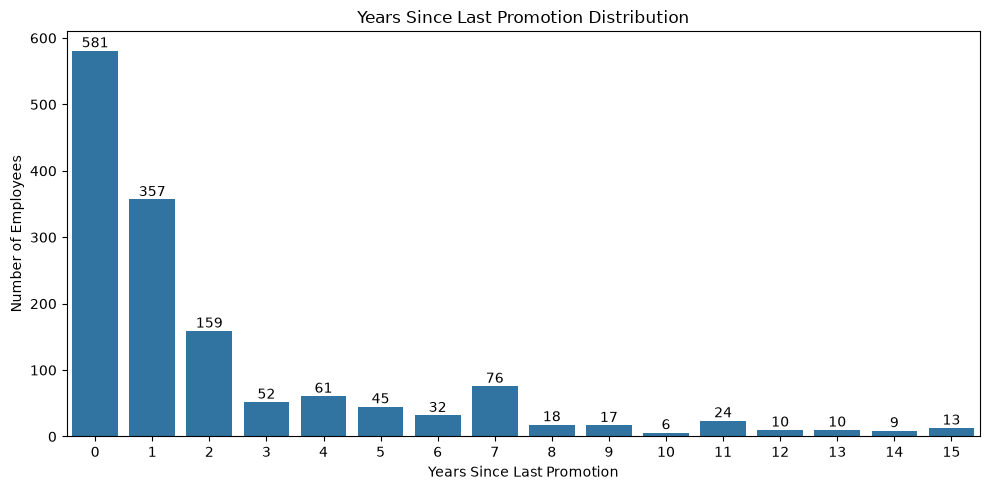

In [66]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=years_since_promotion_counts.index,
    y=years_since_promotion_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Years Since Last Promotion Distribution")
plt.xlabel("Years Since Last Promotion")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

**Observation:** Most sampled employees received their latest promotion within the past 0–2 years, suggesting that recent promotions are relatively common. Another noticeable concentration appears at 7 years since the last promotion, although this distribution alone does not explain the reason for that recurring pattern.

## 14. Years with Current Manager

In [67]:
years_with_manager_counts = (
    df["YearsWithCurrManager"]
    .value_counts()
    .sort_index()
)

years_with_manager_counts

YearsWithCurrManager
0     263
1      76
2     344
3     142
4      98
5      31
6      29
7     216
8     107
9      64
10     27
11     22
12     18
13     14
14      5
15      5
16      2
17      7
Name: count, dtype: int64

In [68]:
years_with_manager_percentages = (
    df["YearsWithCurrManager"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

years_with_manager_percentages

YearsWithCurrManager
0     17.89
1      5.17
2     23.40
3      9.66
4      6.67
5      2.11
6      1.97
7     14.69
8      7.28
9      4.35
10     1.84
11     1.50
12     1.22
13     0.95
14     0.34
15     0.34
16     0.14
17     0.48
Name: proportion, dtype: float64

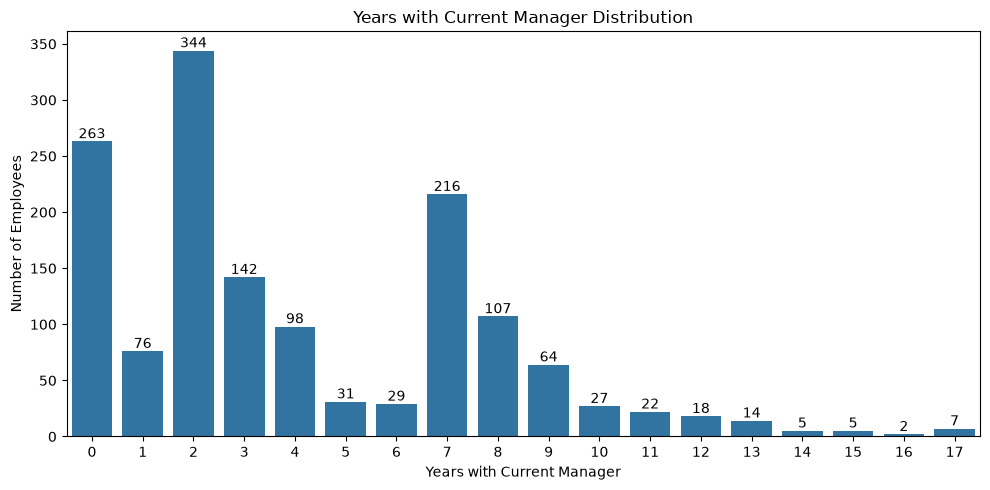

In [69]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=years_with_manager_counts.index,
    y=years_with_manager_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Years with Current Manager Distribution")
plt.xlabel("Years with Current Manager")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

**Observation:** The distribution shows noticeable concentrations at 0, 2, and 7 years with the current manager. The high number at 0 years may reflect recently hired employees, recent role changes, or changes in management. The recurring peak at 7 years is also visible in other tenure-related variables, suggesting a broader pattern in employee career timelines within the sampled workforce.

## 15. Monthly Income Distribution

In [70]:
df["MonthlyIncome"].describe()

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

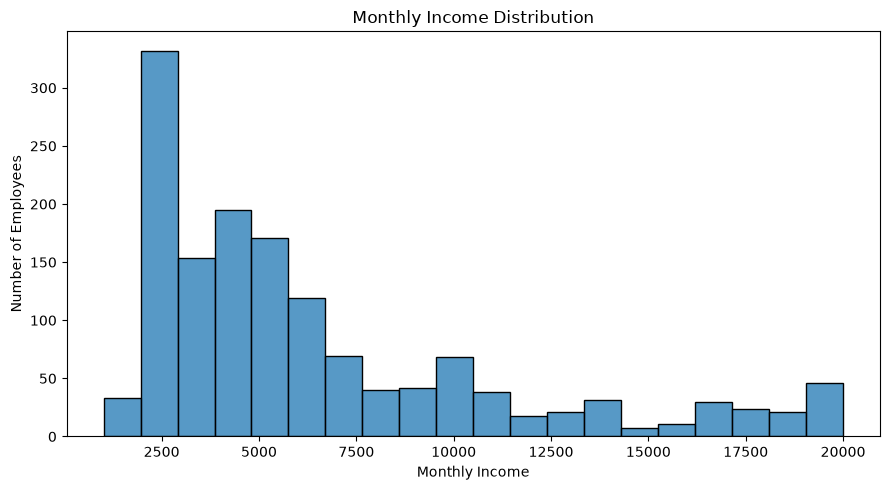

In [71]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="MonthlyIncome",
    bins=20
)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

In [72]:
income_group_order = [
    "Under 3000",
    "3000–4999",
    "5000–7999",
    "8000–11999",
    "12000–15999",
    "16000+"
]

In [73]:
income_group_counts = (
    df["IncomeGroup"]
    .value_counts()
    .reindex(income_group_order)
)

income_group_counts

IncomeGroup
Under 3000     395
3000–4999      354
5000–7999      340
8000–11999     186
12000–15999     69
16000+         126
Name: count, dtype: int64

In [74]:
income_group_percentages = (
    df["IncomeGroup"]
    .value_counts(normalize=True)
    .reindex(income_group_order)
    .mul(100)
    .round(2)
)

income_group_percentages

IncomeGroup
Under 3000     26.87
3000–4999      24.08
5000–7999      23.13
8000–11999     12.65
12000–15999     4.69
16000+          8.57
Name: proportion, dtype: float64

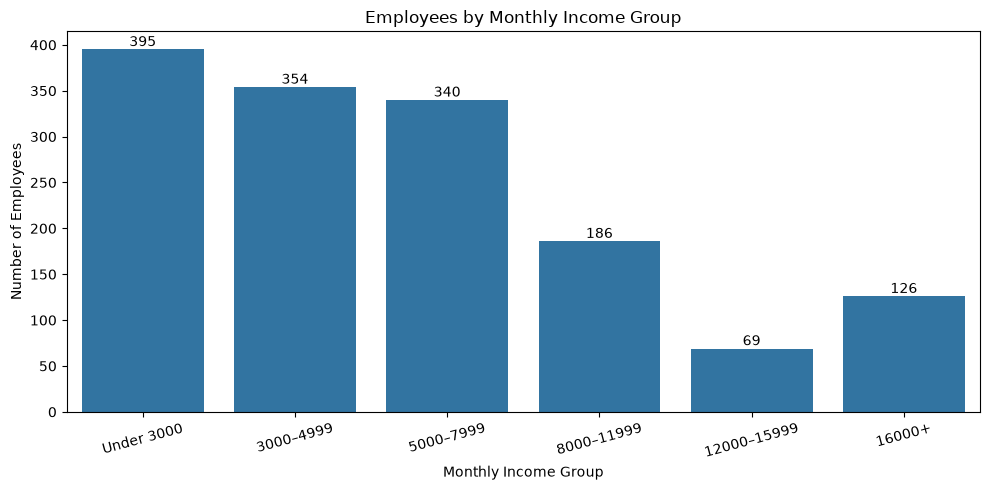

In [75]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=income_group_counts.index,
    y=income_group_counts.values
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Employees by Monthly Income Group")
plt.xlabel("Monthly Income Group")
plt.ylabel("Number of Employees")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

**Observation:** Most employees in the sampled workforce are concentrated in the lower and middle monthly income ranges, particularly below 8,000. The number of employees generally decreases across the higher income groups, with comparatively few employees earning 12,000 or more per month.